In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import scipy.sparse, os, warnings
warnings.simplefilter("ignore")
from glob import glob
from sklearn.metrics import mean_squared_error
import stan

In [2]:
sample_list = []
for x in glob('data/Sonpatki_processed/*'):
    sample_list.append(x.split(r'/')[-1][:-5])
sample_list.sort()

sample_list

['SNU16A',
 'SNU16B',
 'SNU17A',
 'SNU17B',
 'SNU18A',
 'SNU18Afrozen',
 'SNU18B',
 'SNU21A',
 'SNU21Afrozen',
 'SNU21B',
 'SNU21Bfrozen',
 'SNU21Cfrozen',
 'SNU21Dfrozen',
 'SNU23A',
 'SNU24A',
 'SNU24B',
 'SNU25A',
 'SNU25B',
 'SNU27A',
 'SNU27B',
 'SNU33A',
 'SNU33B',
 'SNU34A',
 'SNU43A',
 'SNU46A',
 'SNU46B',
 'SNU51A',
 'SNU51B']

In [3]:
adatas = dict()
for sample in sample_list:
    adatas[sample] = sc.read_h5ad(f"data/Sonpatki_processed/{sample}.h5ad")

In [4]:
data_list = []
for sample, adata in adatas.items():
    if scipy.sparse.issparse(adata.X):
        n_genes = adata.X.astype(bool).sum(axis=1).A1
    else:
        n_genes = (adata.X > 0).sum(axis=1)
    total_counts = adata.obs['n_counts'].copy()
    
    df = pd.DataFrame({
        'sample': sample,
        'n_genes': n_genes,
        'total_counts': total_counts
    })
    data_list.append(df)

df_all = pd.concat(data_list, ignore_index=True)

In [5]:
df_all

,sample,n_genes,total_counts
0,SNU16A,2802,4966.0
1,SNU16A,4836,9461.0
2,SNU16A,2810,4740.0
3,SNU16A,3294,5853.0
4,SNU16A,3081,5264.0
...,...,...,...
107534,SNU51B,5311,13022.0
107535,SNU51B,7804,29136.0
107536,SNU51B,7014,22752.0
107537,SNU51B,7293,24322.0


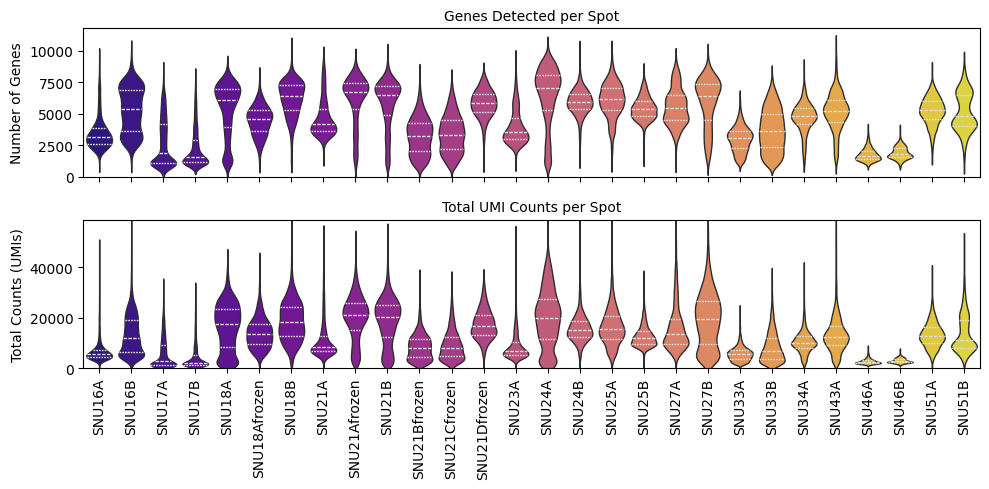

In [6]:
dpi = 300
fontsize = 8
figsize = 2.5

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(figsize*4, figsize*2), sharex=True)

sns.violinplot(
    data=df_all,
    x='sample',
    y='n_genes',
    ax=ax1,
    palette='plasma', 
    inner='quartile', linewidth=1,
    inner_kws={'color': '#DDDDDD'}
)
ax1.set_title('Genes Detected per Spot', fontsize=10)
ax1.set_ylabel('Number of Genes')
# ax1.yaxis.grid(True)
ax1.set_ylim([0, 11800])


sns.violinplot(
    data=df_all,
    x='sample',
    y='total_counts',
    ax=ax2,
    palette='plasma',
    inner='quartile', linewidth=1,
    inner_kws={'color': '#DDDDDD'}
)
ax2.set_title('Total UMI Counts per Spot', fontsize=10)
ax2.set_ylabel('Total Counts (UMIs)')
ax2.set_xlabel('')
ax2.tick_params(axis='x', rotation=90)
# ax2.yaxis.grid(True)
ax2.set_ylim([0, 11800*5])

plt.tight_layout()
plt.savefig('plots_manuscript_v2/qc_sonpatki.pdf')
plt.show()

In [7]:
sample_means = df_all.groupby('sample').agg({
    'n_genes': 'mean',
    'total_counts': 'mean'
}).reset_index()
sample_means

,sample,n_genes,total_counts
0,SNU16A,3464.849852,6718.098633
1,SNU16B,5318.209110,13230.059570
2,SNU17A,2706.072283,5922.670410
3,SNU17B,2256.314366,4376.480957
4,SNU18A,5341.826489,16227.542969
5,SNU18Afrozen,4463.090503,13914.443359
6,SNU18B,6208.283453,18768.605469
7,SNU21A,4704.113887,11218.222656
8,SNU21Afrozen,6121.033933,20016.712891
9,SNU21B,5808.610294,18632.072266


In [8]:
filtered_samples = sample_means[
    (sample_means['n_genes'] > 3000) & 
    (sample_means['total_counts'] > 12000)
]['sample'].tolist()
filtered_samples

['SNU16B',
 'SNU18A',
 'SNU18Afrozen',
 'SNU18B',
 'SNU21Afrozen',
 'SNU21B',
 'SNU21Dfrozen',
 'SNU24A',
 'SNU24B',
 'SNU25A',
 'SNU25B',
 'SNU27A',
 'SNU27B',
 'SNU43A',
 'SNU51A',
 'SNU51B']

In [9]:
sample_list = ['SNU16B',
 'SNU18A',
 'SNU18Afrozen',
 'SNU18B',
 'SNU21Afrozen',
 'SNU21B',
 'SNU21Dfrozen',
 'SNU24A',
 'SNU24B',
 'SNU25A',
 'SNU25B',
 'SNU27A',
 'SNU27B',
 'SNU43A',
 'SNU51A',
 'SNU51B']

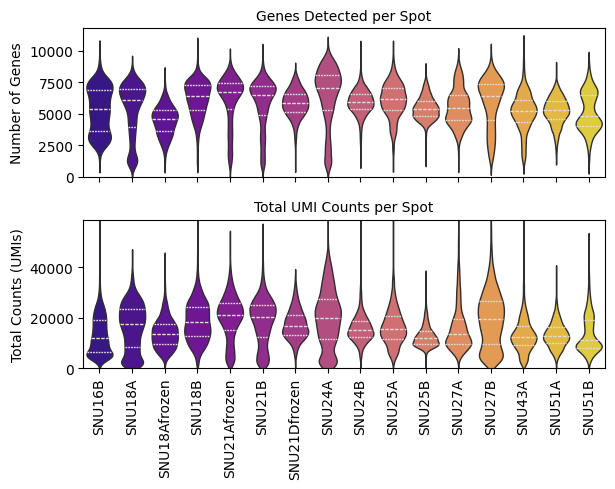

In [10]:
dpi = 300
fontsize = 8
figsize = 2.5

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(figsize*2.5, figsize*2), sharex=True)

sns.violinplot(
    data=df_all[df_all['sample'].isin(sample_list)],
    x='sample',
    y='n_genes',
    ax=ax1,
    palette='plasma', 
    inner='quartile', linewidth=1,
    inner_kws={'color': '#DDDDDD'}
)
ax1.set_title('Genes Detected per Spot', fontsize=10)
ax1.set_ylabel('Number of Genes')
# ax1.yaxis.grid(True)
ax1.set_ylim([0, 11800])


sns.violinplot(
    data=df_all[df_all['sample'].isin(sample_list)],
    x='sample',
    y='total_counts',
    ax=ax2,
    palette='plasma',
    inner='quartile', linewidth=1,
    inner_kws={'color': '#DDDDDD'}
)
ax2.set_title('Total UMI Counts per Spot', fontsize=10)
ax2.set_ylabel('Total Counts (UMIs)')
ax2.set_xlabel('')
ax2.tick_params(axis='x', rotation=90)
# ax2.yaxis.grid(True)
ax2.set_ylim([0, 11800*5])

plt.tight_layout()
plt.savefig('plots_manuscript/qc_sonpatki_subset.pdf')
plt.show()

## Infer TF Activity
### Loading the TF-gene prior

In [11]:
adatas = dict()
for sample in sample_list:
    adatas[sample] = sc.read_h5ad(f"data/Sonpatki_processed/{sample}.h5ad")
    adatas[sample] = stan.add_gene_tf_matrix(adatas[sample],
                                            min_cells_proportion = 0.1,
                                            min_tfs_per_gene= 10,
                                            min_genes_per_tf= 5,
                                            gene_tf_source="hTFtarget",
                                            tf_list="humantfs",
                                            source_dir="resources/")

In [12]:
df_size = []
for sample in filtered_samples:
    D = adatas[sample].varm['gene_tf']
    Y = adatas[sample].to_df()
    df_size.append([D.shape[1], Y.shape[1], Y.shape[0],
                   D.T.abs().sum().min(),
                   D.abs().sum().min(),
                   (Y>0).sum().min(),
                   (Y>0).T.sum().min()])

df_size = pd.DataFrame(df_size, index=sample_list,
                      columns = ['TFs', 'Genes', 'Cells',
                                 'TFs_per_Gene', 'Genes_per_TF',
                                 'Cells_per_Gene', 'Genes_per_Cell'])
df_size

,TFs,Genes,Cells,TFs_per_Gene,Genes_per_TF,Cells_per_Gene,Genes_per_Cell
SNU16B,239,9594,3864,10.0,5.0,387,899
SNU18A,238,9595,2922,10.0,5.0,293,662
SNU18Afrozen,247,9275,4696,10.0,5.0,470,666
SNU18B,238,9918,2653,10.0,5.0,266,795
SNU21Afrozen,240,10187,2446,10.0,5.0,245,591
SNU21B,239,9728,4488,10.0,5.0,449,648
SNU21Dfrozen,244,10026,3469,10.0,5.0,347,714
SNU24A,237,9986,3615,10.0,5.0,362,709
SNU24B,247,9701,4210,10.0,5.0,421,910
SNU25A,229,9826,2613,10.0,5.0,262,813


### Computing the spatially dependent kernel

In [13]:
for sample in sample_list:
    stan.pixel_intensity(adatas[sample], windowsize=25)
    stan.make_kernel_from_pixel(adatas[sample], n=250, im_feats_weight=0.05)
    sc.pp.normalize_total(adatas[sample])
    adatas[sample].layers['scaled'] = np.sqrt(adatas[sample].to_df())

### Running STAN

In [14]:
df_corr = []
paras_dict_tfa = {}

for sample in sample_list:
    print(sample)
    stan.assign_folds(adatas[sample], n_folds=10, random_seed=0)
    stan_model = stan.Stan(adatas[sample], layer='scaled')
    stan_model.fit(n_steps=7, stages=1,
                  grid_search_params={'lam1':[1000],'lam2':[1e-3, 1e3]})
    paras_dict_tfa[sample] = stan_model.params

    cor = stan_model.evaluate(fold=-1)
    adatas[sample].obs['pred_cor_stan'] = cor
    adatas[sample].obsm['tfa_stan'] = pd.DataFrame(stan_model.W_concat.T, 
                                                    index=adatas[sample].obs_names, 
                                                    columns=adatas[sample].uns['tf_names'])
    
    Y = adatas[sample].varm['gene_tf'].dot(stan_model.W_concat)
    mse = mean_squared_error(Y, adatas[sample].to_df('scaled').T)
    df_corr.append([round(np.nanmean(cor), 4), mse])

df_corr = pd.DataFrame(df_corr, index=sample_list,columns = ['spot_corr', 'mse'])

SNU16B
Time elapsed: 44.99 seconds
SNU18A
Time elapsed: 96.20 seconds
SNU18Afrozen
Time elapsed: 38.95 seconds
SNU18B
Time elapsed: 23.11 seconds
SNU21Afrozen
Time elapsed: 21.39 seconds
SNU21B
Time elapsed: 39.39 seconds
SNU21Dfrozen
Time elapsed: 29.71 seconds
SNU24A
Time elapsed: 29.35 seconds
SNU24B
Time elapsed: 34.92 seconds
SNU25A
Time elapsed: 20.07 seconds
SNU25B
Time elapsed: 31.24 seconds
SNU27A
Time elapsed: 30.44 seconds
SNU27B
Time elapsed: 45.60 seconds
SNU43A
Time elapsed: 978.38 seconds
SNU51A
Time elapsed: 34.59 seconds
SNU51B
Time elapsed: 30.94 seconds


In [15]:
paras_dict_tfa

{'SNU16B': {'lam2': 1000.0, 'lam1': 1000},
 'SNU18A': {'lam2': 1000.0, 'lam1': 1000},
 'SNU18Afrozen': {'lam2': 10.0, 'lam1': 1000},
 'SNU18B': {'lam2': 1000.0, 'lam1': 1000},
 'SNU21Afrozen': {'lam2': 1000.0, 'lam1': 1000},
 'SNU21B': {'lam2': 1000.0, 'lam1': 1000},
 'SNU21Dfrozen': {'lam2': 1000.0, 'lam1': 1000},
 'SNU24A': {'lam2': 1000.0, 'lam1': 1000},
 'SNU24B': {'lam2': 1000.0, 'lam1': 1000},
 'SNU25A': {'lam2': 1000.0, 'lam1': 1000},
 'SNU25B': {'lam2': 1000.0, 'lam1': 1000},
 'SNU27A': {'lam2': 1000.0, 'lam1': 1000},
 'SNU27B': {'lam2': 1000.0, 'lam1': 1000},
 'SNU43A': {'lam2': 1000.0, 'lam1': 1000},
 'SNU51A': {'lam2': 1000.0, 'lam1': 1000},
 'SNU51B': {'lam2': 0.1, 'lam1': 1000}}

In [16]:
df_corr

,spot_corr,mse
SNU16B,0.1413,0.624696
SNU18A,0.1767,0.939851
SNU18Afrozen,0.2609,0.824746
SNU18B,0.1832,0.884920
SNU21Afrozen,0.2013,1.067720
SNU21B,0.1646,1.054788
SNU21Dfrozen,0.1909,0.873053
SNU24A,0.1601,0.936403
SNU24B,0.1183,0.756825
SNU25A,0.1402,0.761047


In [17]:
path = 'results'
if not os.path.exists(path):
    os.mkdir(path)
    
path = 'results/sonpatki_tfa'
if not os.path.exists(path):
    os.mkdir(path)
    
for sample in sample_list:
    adatas[sample].write(f"{path}/{sample}.h5ad")

## Infer Pathway Activity
### Loading the pathway-gene prior

In [18]:
path2remove = ['HALLMARK_ADIPOGENESIS',
               'HALLMARK_MYOGENESIS',
               'HALLMARK_PANCREAS_BETA_CELLS',
               'HALLMARK_SPERMATOGENESIS',
               'HALLMARK_BILE_ACID_METABOLISM']

In [19]:
adatas = dict()
for sample in sample_list:
    adatas[sample] = sc.read_h5ad(f"data/Sonpatki_processed/{sample}.h5ad")
    adatas[sample] = stan.add_gene_pw_matrix(adatas[sample],
                                             min_cells_proportion = 0.1,
                                             path2remove = path2remove,
                                             source_dir="resources/")

In [20]:
df_size = []
for sample in sample_list:
    D = adatas[sample].varm['gene_pw']
    Y = adatas[sample].to_df()
    df_size.append([D.shape[1], Y.shape[1], Y.shape[0],
                   D.T.abs().sum().min(),
                   D.abs().sum().min(),
                   (Y>0).sum().min(),
                   (Y>0).T.sum().min()])

df_size = pd.DataFrame(df_size, index=sample_list,
                      columns = ['Pathways', 'Genes', 'Cells',
                                 'PWs_per_Gene', 'Genes_per_PW',
                                 'Cells_per_Gene', 'Genes_per_Cell'])
df_size

,Pathways,Genes,Cells,PWs_per_Gene,Genes_per_PW,Cells_per_Gene,Genes_per_Cell
SNU16B,45,2925,3864,1.0,24.0,388,349
SNU18A,45,3052,2922,1.0,29.0,293,265
SNU18Afrozen,45,2936,4696,1.0,23.0,470,285
SNU18B,45,3118,2653,1.0,29.0,269,342
SNU21Afrozen,45,3134,2446,1.0,26.0,245,256
SNU21B,45,3057,4488,1.0,29.0,450,269
SNU21Dfrozen,45,3091,3469,1.0,26.0,348,275
SNU24A,45,3106,3615,1.0,25.0,364,267
SNU24B,45,2926,4210,1.0,23.0,423,356
SNU25A,45,3033,2613,1.0,25.0,262,351


### Computing the spatially dependent kernel

In [21]:
for sample in sample_list:
    stan.pixel_intensity(adatas[sample], windowsize=25)
    stan.make_kernel_from_pixel(adatas[sample], n=250, im_feats_weight=0.05)
    sc.pp.normalize_total(adatas[sample])
    adatas[sample].layers['scaled'] = np.sqrt(adatas[sample].to_df())

### Running STAN

In [22]:
df_corr = []
paras_dict_pwa = {}

for sample in sample_list:
    print(sample)
    stan.assign_folds(adatas[sample], n_folds=10, random_seed=0)
    stan_model = stan.Stan(adatas[sample], layer='scaled', prior='gene_pw')
    stan_model.fit(n_steps=7, stages=1,
                  grid_search_params={'lam1':[1000],'lam2':[1e-3, 1e3]})
    paras_dict_pwa[sample] = stan_model.params

    cor = stan_model.evaluate(fold=-1)
    adatas[sample].obs['pred_cor_stan'] = cor
    adatas[sample].obsm['pwa_stan'] = pd.DataFrame(stan_model.W_concat.T, 
                                                    index=adatas[sample].obs_names, 
                                                    columns=adatas[sample].uns['pw_names'])
    
    Y = adatas[sample].varm['gene_pw'].dot(stan_model.W_concat)
    mse = mean_squared_error(Y, adatas[sample].to_df('scaled').T)
    df_corr.append([round(np.nanmean(cor), 4), mse])
    
df_corr = pd.DataFrame(df_corr, index=sample_list, columns = ['spot_corr', 'mse'])

SNU16B
Time elapsed: 7.15 seconds
SNU18A
Time elapsed: 5.26 seconds
SNU18Afrozen
Time elapsed: 8.88 seconds
SNU18B
Time elapsed: 4.72 seconds
SNU21Afrozen
Time elapsed: 4.30 seconds
SNU21B
Time elapsed: 8.56 seconds
SNU21Dfrozen
Time elapsed: 6.46 seconds
SNU24A
Time elapsed: 6.61 seconds
SNU24B
Time elapsed: 7.77 seconds
SNU25A
Time elapsed: 4.65 seconds
SNU25B
Time elapsed: 8.00 seconds
SNU27A
Time elapsed: 7.48 seconds
SNU27B
Time elapsed: 8.48 seconds
SNU43A
Time elapsed: 11.19 seconds
SNU51A
Time elapsed: 11.40 seconds
SNU51B
Time elapsed: 11.37 seconds


In [23]:
paras_dict_pwa

{'SNU16B': {'lam2': 0.001, 'lam1': 1000},
 'SNU18A': {'lam2': 0.001, 'lam1': 1000},
 'SNU18Afrozen': {'lam2': 0.001, 'lam1': 1000},
 'SNU18B': {'lam2': 0.001, 'lam1': 1000},
 'SNU21Afrozen': {'lam2': 0.001, 'lam1': 1000},
 'SNU21B': {'lam2': 0.001, 'lam1': 1000},
 'SNU21Dfrozen': {'lam2': 0.001, 'lam1': 1000},
 'SNU24A': {'lam2': 0.01, 'lam1': 1000},
 'SNU24B': {'lam2': 0.001, 'lam1': 1000},
 'SNU25A': {'lam2': 0.001, 'lam1': 1000},
 'SNU25B': {'lam2': 0.001, 'lam1': 1000},
 'SNU27A': {'lam2': 0.001, 'lam1': 1000},
 'SNU27B': {'lam2': 0.001, 'lam1': 1000},
 'SNU43A': {'lam2': 0.001, 'lam1': 1000},
 'SNU51A': {'lam2': 0.001, 'lam1': 1000},
 'SNU51B': {'lam2': 0.001, 'lam1': 1000}}

In [24]:
df_corr   

,spot_corr,mse
SNU16B,0.1400,0.894455
SNU18A,0.2126,1.562782
SNU18Afrozen,0.1542,1.138114
SNU18B,0.2132,1.436269
SNU21Afrozen,0.1828,1.541960
SNU21B,0.1924,1.891846
SNU21Dfrozen,0.1794,1.250047
SNU24A,0.1561,1.436214
SNU24B,0.1201,1.139210
SNU25A,0.1318,1.184012


In [25]:
path = 'results/sonpatki_pwa'
if not os.path.exists(path):
    os.mkdir(path)
    
for sample in sample_list:
    adatas[sample].write(f"{path}/{sample}.h5ad")